# Mechanistic interpretability: manuscript figures

Redraw the main five-panel mechanism figure and the paired supplementary grid diagnostics.


In [ ]:
# Mechanistic figure implementation (kept here as the single source of truth).
import types

_panel_source = '#!/usr/bin/env python3\n"""Draw the four-panel mechanistic-interpretability figure directly with Matplotlib."""\nfrom __future__ import annotations\n\nimport json\nfrom pathlib import Path\n\nimport matplotlib\n\nmatplotlib.use("Agg")\nimport matplotlib.pyplot as plt\nimport numpy as np\nimport pandas as pd\nfrom matplotlib.patches import Patch\n\n\nHERE = Path(__file__).resolve().parent\nRESULTS = HERE / "results"\nHISTORY_RESULTS = HERE.parent / "figure" / "results_legal_growth_histories"\nOUTPUT = HERE.parent / "figure" / "abtab2_interpretability_statistics"\nEDGE_ORDER = ["A1", "B1", "A2", "B2", "B3"]\nCOLORS = {\n    "blue": "#4C93C3",\n    "orange": "#E9780D",\n    "teal": "#1CB39E",\n    "purple": "#9B75CC",\n    "red": "#E15759",\n    "ink": "#222222",\n}\n\n\ndef configure_style() -> None:\n    plt.rcParams.update({\n        "font.family": "sans-serif",\n        "font.sans-serif": ["Arial", "DejaVu Sans"],\n        "mathtext.fontset": "dejavusans",\n        "font.size": 8.5,\n        "axes.labelsize": 9.5,\n        "legend.fontsize": 8,\n        "xtick.labelsize": 8.5,\n        "ytick.labelsize": 8.5,\n        "axes.linewidth": 1.0,\n        "xtick.major.width": 1.0,\n        "ytick.major.width": 1.0,\n        "xtick.major.size": 4,\n        "ytick.major.size": 4,\n        "legend.frameon": False,\n        "savefig.dpi": 600,\n    })\n\n\ndef representative_rows() -> tuple[pd.DataFrame, pd.DataFrame]:\n    edges = pd.read_csv(RESULTS / "abtab2_rpa_edge_influence.csv")\n    deletion = pd.read_csv(RESULTS / "abtab2_gnnexplainer_edge_summary.csv")\n    edges = edges[np.isclose(edges.f_A, 0.5) & np.isclose(edges.rho, 1.0)].copy()\n    deletion = deletion[np.isclose(deletion.f_A, 0.5) & np.isclose(deletion.rho, 1.0)].copy()\n    for frame in (edges, deletion):\n        frame["edge"] = pd.Categorical(frame.edge, EDGE_ORDER, ordered=True)\n        frame.sort_values("edge", inplace=True)\n    assert edges.edge.astype(str).tolist() == EDGE_ORDER\n    assert deletion.edge.astype(str).tolist() == EDGE_ORDER\n    return edges, deletion\n\n\ndef style_axis(ax: plt.Axes) -> None:\n    ax.tick_params(direction="in", top=True, right=True)\n    for spine in ax.spines.values():\n        spine.set_color(COLORS["ink"])\n\n\ndef panel_a(ax: plt.Axes, edges: pd.DataFrame) -> None:\n    x = np.arange(len(edges))\n    width = 0.22\n    specs = [\n        ("I_self", r"$I_{\\mathrm{self}}$", COLORS["blue"]),\n        ("I_junction", r"$I_{\\mathrm{junction}}$", COLORS["orange"]),\n        ("I_separated", r"$I_{\\mathrm{separated}}$", COLORS["teal"]),\n    ]\n    for offset, (column, label, color) in zip((-width, 0, width), specs):\n        ax.bar(x + offset, edges[column], width * 0.92, color=color,\n               edgecolor=COLORS["ink"], linewidth=0.55, label=label)\n    ax.axhline(0, color=COLORS["ink"], linewidth=0.8)\n    ax.set(xticks=x, xticklabels=EDGE_ORDER, xlabel="Block edge",\n           ylabel=r"Signed RPA component $I_e$", ylim=(-12.5, 8.5))\n    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.15), ncol=3,\n              columnspacing=1.0, handletextpad=0.4)\n    style_axis(ax)\n\n\ndef panel_b(ax: plt.Axes, edges: pd.DataFrame, deletion: pd.DataFrame) -> None:\n    x = np.arange(len(edges))\n    width = 0.34\n    ax.bar(x - width / 2, -edges.I_total, width, color=COLORS["purple"],\n           edgecolor=COLORS["ink"], linewidth=0.55)\n    ax.set(xticks=x, xticklabels=EDGE_ORDER, xlabel="Block edge",\n           ylabel=r"Aggregate RPA influence $-I_e^{\\mathrm{RPA}}$", ylim=(0, 10))\n    style_axis(ax)\n\n    ax2 = ax.twinx()\n    ax2.bar(x + width / 2, deletion.deletion_mean, width, color=COLORS["red"],\n            edgecolor=COLORS["ink"], linewidth=0.55)\n    ax2.set_ylabel(r"Deletion effect $F_e$")\n    ax2.set_ylim(0, 5)\n    style_axis(ax2)\n    handles = [\n        Patch(facecolor=COLORS["purple"], edgecolor=COLORS["ink"],\n              label=r"aggregate $-I_e^{\\mathrm{RPA}}$"),\n        Patch(facecolor=COLORS["red"], edgecolor=COLORS["ink"],\n              label=r"deletion $F_e$"),\n    ]\n    ax.legend(handles=handles, loc="upper right")\n\n\ndef panel_c(ax: plt.Axes) -> None:\n    probe = pd.read_csv(RESULTS / "abtab2_layerwise_probe.csv")\n    specs = [\n        ("S_AA", r"$S_{AA}$", COLORS["blue"]),\n        ("S_BB", r"$S_{BB}$", COLORS["orange"]),\n        ("S_AB", r"$S_{AB}$", COLORS["teal"]),\n        ("q_star", r"$k^*$", COLORS["purple"]),\n        ("chiN_star", r"$\\chi N^*$", COLORS["red"]),\n    ]\n    for concept, label, color in specs:\n        rows = probe[probe.concept.eq(concept)].sort_values("layer")\n        ax.plot(rows.layer, rows.R2_grouped_by_rho, "o-", color=color,\n                markerfacecolor="white", markeredgewidth=0.9, linewidth=1.6,\n                markersize=4.2, label=label)\n    ax.axhline(0, color="#888888", linewidth=0.7)\n    ax.set_xlabel("GINE layer")\n    ax.set_ylabel(r"PCA--ridge probe $R^2$ (LO-$\\rho$)")\n    ax.set_xticks(range(6), ["Input", "GINE-1", "GINE-2", "GINE-3", "GINE-4", "GINE-5"])\n    ax.set_ylim(min(-1.35, probe.R2_grouped_by_rho.min() - 0.05), 1.05)\n    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.17), ncol=5,\n              columnspacing=0.55, handlelength=1.3, handletextpad=0.25)\n    style_axis(ax)\n\n\ndef panel_d(ax: plt.Axes) -> None:\n    summary = json.loads((HISTORY_RESULTS / "summary.json").read_text(encoding="utf-8"))\n    rows = [row for row in summary["summary"] if row["layer"] > 0]\n    assert len(rows) == 5 and {row["n_pairs"] for row in rows} == {16065}\n    values = np.array([row["spearman_mean_embedding_vs_RPA_path"] for row in rows])\n    labels = [f"GINE-{row[\'layer\']}" for row in rows]\n    y = np.arange(len(rows))\n    colors = [COLORS["blue"]] * 4 + [COLORS["red"]]\n    bars = ax.barh(y, values, height=0.58, color=colors,\n                   edgecolor=COLORS["ink"], linewidth=0.55)\n    ax.set(yticks=y, yticklabels=labels, xlabel=r"Path Spearman $\\rho_s$",\n           ylabel="GINE layer", xlim=(0, 1), ylim=(-0.6, 4.6))\n    for bar, value in zip(bars, values):\n        ax.text(value + 0.015, bar.get_y() + bar.get_height() / 2,\n                f"{value:.3f}", va="center", fontsize=8.5)\n    style_axis(ax)\n\n\ndef main() -> None:\n    configure_style()\n    edges, deletion = representative_rows()\n    fig, axes = plt.subplots(2, 2, figsize=(7.16, 6.0))\n    panel_a(axes[0, 0], edges)\n    panel_b(axes[0, 1], edges, deletion)\n    panel_c(axes[1, 0])\n    panel_d(axes[1, 1])\n    for label, ax in zip("abcd", axes.flat):\n        ax.text(-0.17, 1.10, f"({label})", transform=ax.transAxes,\n                fontsize=13, fontweight="bold", va="top")\n    fig.subplots_adjust(left=0.10, right=0.91, bottom=0.09, top=0.94,\n                        wspace=0.42, hspace=0.42)\n    fig.savefig(OUTPUT.with_suffix(".png"), dpi=600, facecolor="white")\n    fig.savefig(OUTPUT.with_suffix(".pdf"), facecolor="white")\n    plt.close(fig)\n    print(f"saved {OUTPUT.with_suffix(\'.png\')} and {OUTPUT.with_suffix(\'.pdf\')}")\n\n\nif __name__ == "__main__":\n    main()\n'
_panel_file = CODE / "scripts/mechanistic_interpretability/plot_interpretability_statistics.py"
_mechanistic_panels = types.ModuleType("_mechanistic_panels")
_mechanistic_panels.__file__ = str(_panel_file)
exec(compile(_panel_source, str(_panel_file), "exec"), _mechanistic_panels.__dict__)

_composer_source = '\ufeff"""Compose the original topology image with four mpltex-styled data panels."""\nfrom pathlib import Path\nimport importlib.util\nimport sys\n\nHERE = Path(__file__).resolve().parent\nCODE = HERE.parents[1]\nSTYLE_DIR = CODE / \'src/plotting\'\nsys.path.insert(0, str(STYLE_DIR))\nfrom paper_style import COLORS, configure_paper_style, save_dual, style_axis\n\nconfigure_paper_style()\nimport matplotlib.pyplot as plt\nimport numpy as np\n\nRESULTS = CODE / \'data/mechanistic_interpretability/rpa\'\nHISTORY_RESULTS = CODE / \'data/mechanistic_interpretability/legal_histories\'\nOUTPUT = CODE / \'results/figures/mechanistic_interpretability/fig5_mechanistic_interpretability\'\nTOPOLOGY_IMAGE = CODE / \'data/mechanistic_interpretability/topology.png\'\n\n\ndef main():\n    source = HERE / \'plot_interpretability_statistics.py\'\n    spec = importlib.util.spec_from_file_location(\'original_mechanistic_panels\', source)\n    plots = importlib.util.module_from_spec(spec)\n    spec.loader.exec_module(plots)\n    plots.RESULTS = RESULTS\n    plots.HISTORY_RESULTS = HISTORY_RESULTS\n    panel_colors = dict(COLORS)\n    panel_colors[\'ink\'] = COLORS[\'black\']\n    plots.COLORS = panel_colors\n    plots.style_axis = style_axis\n    edges, deletion = plots.representative_rows()\n\n    fig = plt.figure(figsize=(26, 13.5), facecolor=\'white\')\n    grid = fig.add_gridspec(2, 3, width_ratios=(0.82, 1, 1),\n                            left=0.055, right=0.965, bottom=0.09, top=0.94,\n                            wspace=0.46, hspace=0.42)\n    axes = {\n        \'a\': fig.add_subplot(grid[:, 0]),\n        \'b\': fig.add_subplot(grid[0, 1]),\n        \'c\': fig.add_subplot(grid[1, 1]),\n        \'d\': fig.add_subplot(grid[0, 2]),\n        \'e\': fig.add_subplot(grid[1, 2]),\n    }\n    image = plt.imread(TOPOLOGY_IMAGE)\n    rgb = image[..., :3]\n    background = (rgb.min(axis=2) > 0.86) & (np.ptp(rgb, axis=2) < 0.08)\n    image = image.copy()\n    image[background, :3] = 1.0\n    occupied = np.any(image[..., :3] < 0.98, axis=2)\n    rows, cols = np.where(occupied)\n    axes[\'a\'].imshow(image[rows.min():rows.max() + 1, cols.min():cols.max() + 1])\n    axes[\'a\'].axis(\'off\')\n    plots.panel_a(axes[\'b\'], edges)\n    plots.panel_b(axes[\'c\'], edges, deletion)\n    plots.panel_c(axes[\'d\'])\n    plots.panel_d(axes[\'e\'])\n    for line in axes[\'d\'].lines:\n        if line.get_marker() not in (None, \'None\', \'\'):\n            line.set_linewidth(2.8)\n            line.set_markersize(7)\n            line.set_markeredgewidth(1.0)\n    for text in axes[\'e\'].texts:\n        text.set_fontsize(24)\n    for label, ax in axes.items():\n        box = ax.get_position()\n        fig.text(box.x0 - 0.025, box.y1 + 0.012, f\'({label})\', fontsize=32,\n                 fontweight=\'bold\', va=\'bottom\', ha=\'left\')\n    OUTPUT.parent.mkdir(parents=True, exist_ok=True)\n    save_dual(fig, OUTPUT, tight=False)\n    fig.savefig(OUTPUT.with_suffix(\'.pdf\'), facecolor=\'white\')\n    plt.close(fig)\n    print(f\'saved {OUTPUT.with_suffix(".png")}, {OUTPUT.with_suffix(".svg")} and {OUTPUT.with_suffix(".pdf")}\')\n\n\nif __name__ == \'__main__\':\n    main()\n'
_composer_source = _composer_source.lstrip('\ufeff')
_composer_source = _composer_source.replace(
    "    source = HERE / 'plot_interpretability_statistics.py'\n"
    "    spec = importlib.util.spec_from_file_location('original_mechanistic_panels', source)\n"
    "    plots = importlib.util.module_from_spec(spec)\n"
    "    spec.loader.exec_module(plots)\n",
    "    plots = _mechanistic_panels\n",
)
_composer_file = CODE / "scripts/mechanistic_interpretability/plot_mechanistic_five_panel.py"
_namespace = {
    "__file__": str(_composer_file),
    "__name__": "__main__",
    "_mechanistic_panels": _mechanistic_panels,
}
exec(compile(_composer_source, str(_composer_file), "exec"), _namespace)



## Combined mechanistic figure
Panel a defines the diagnostic topology. Panels b--e show the RPA decomposition, edge-level RPA--GNN alignment, layerwise probes and block-placement alignment.

In [2]:
FIGURES = CODE / 'results/figures/mechanistic_interpretability'
display(Image(filename=str(FIGURES / 'fig5_mechanistic_interpretability.png'), width=1000))

## Supplementary Fig. S7: grid-wise robustness
Panel a shows edge-level RPA--GNN alignment; panel b shows final-layer path-representation alignment. Both use the same $9\times5$ $(f_A,\rho)$ grid and a shared Spearman scale.


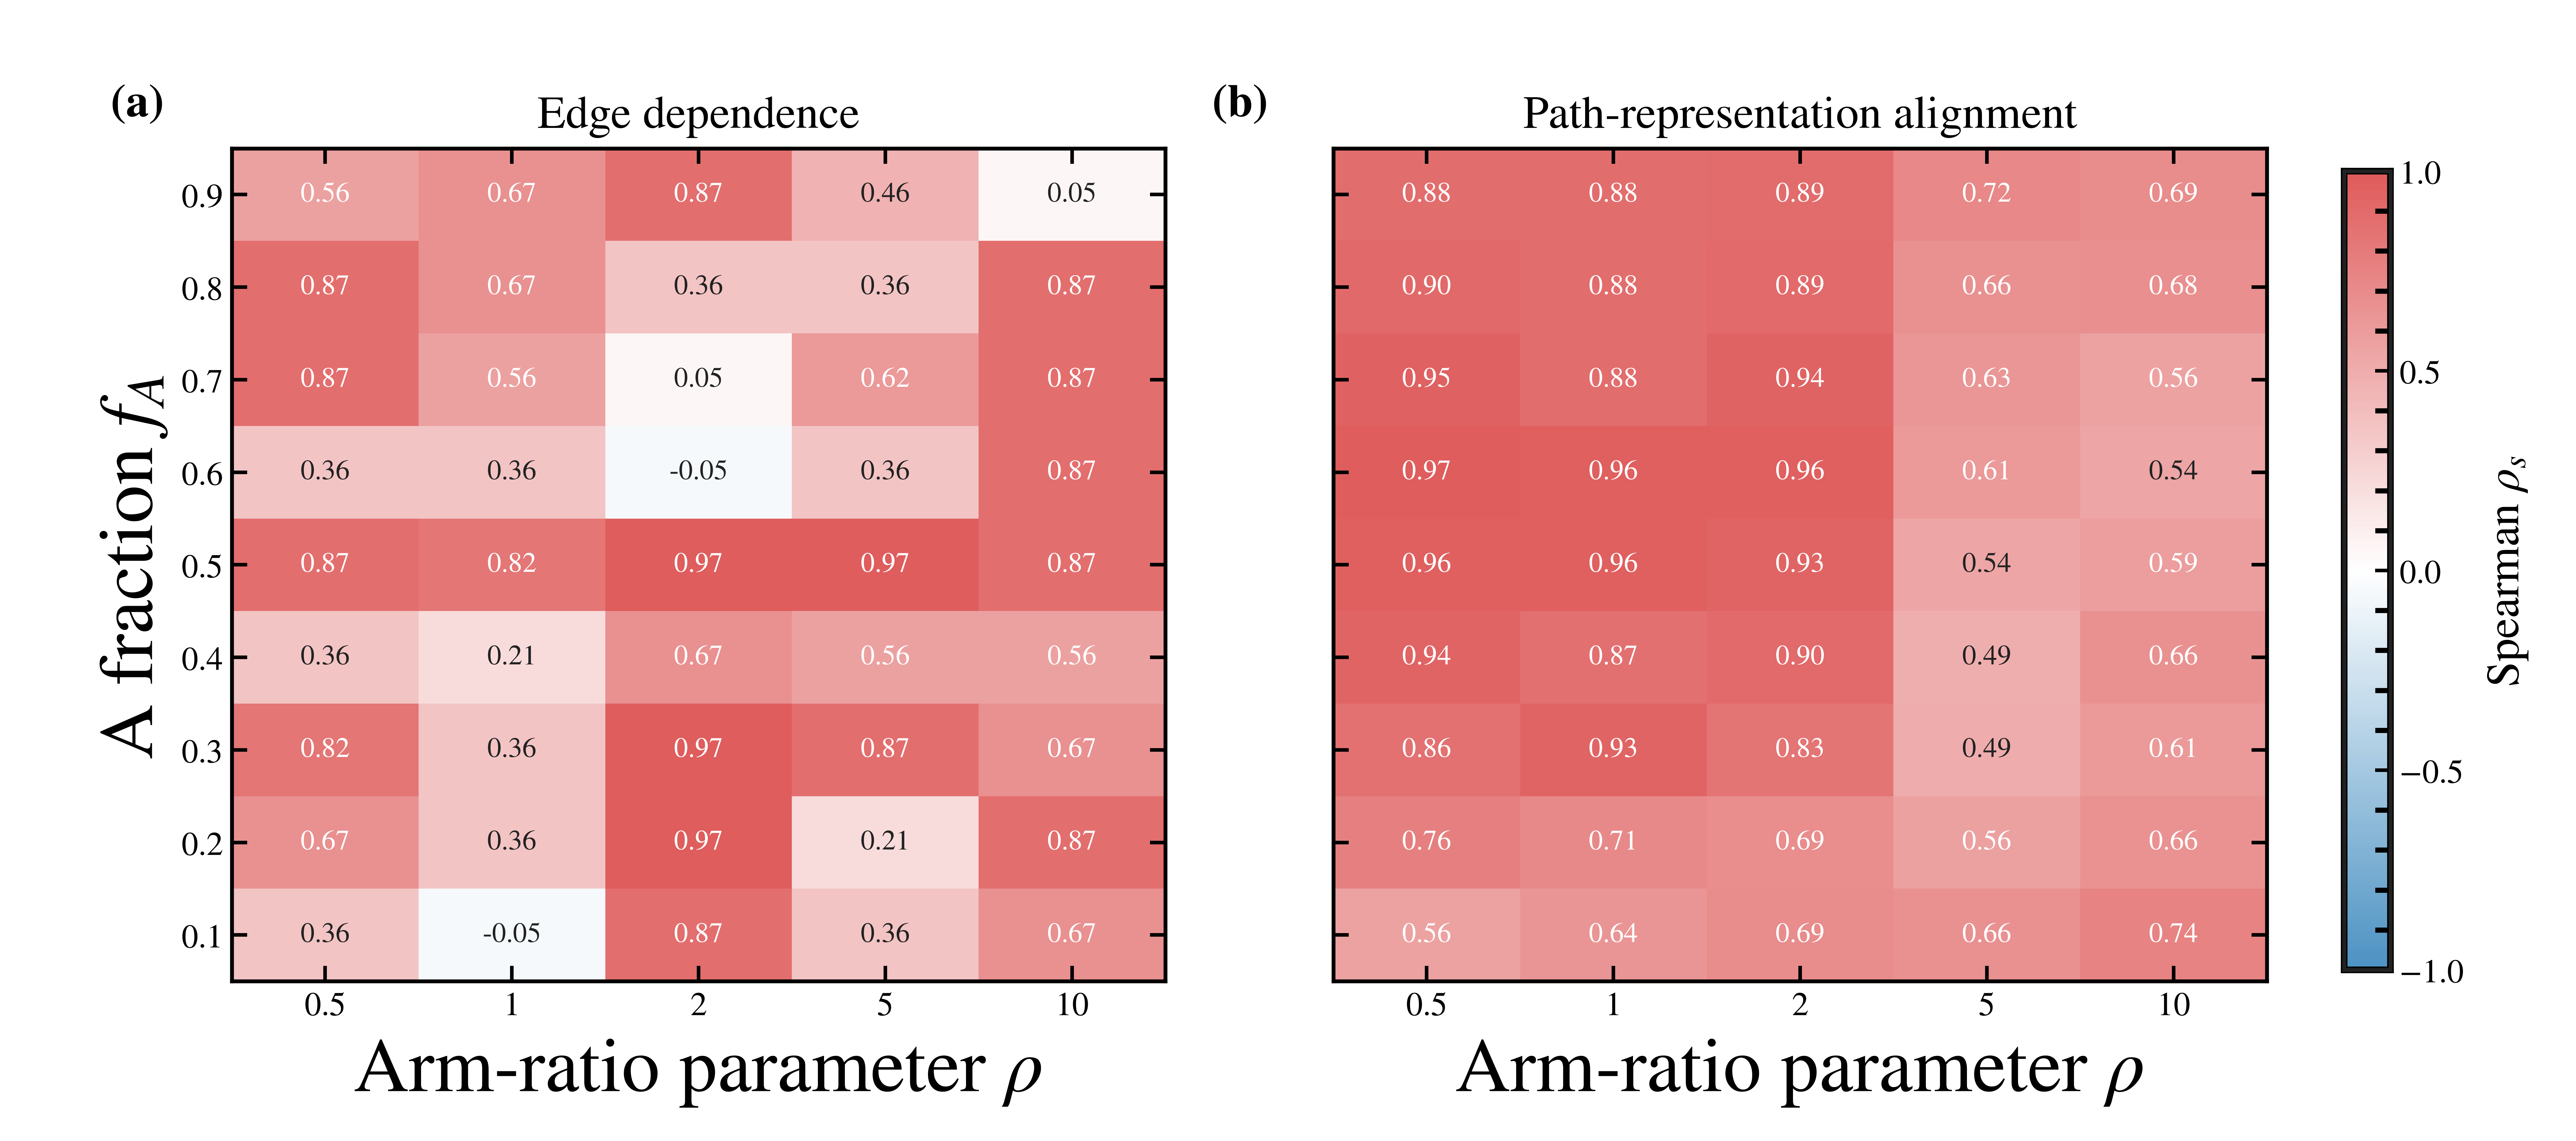

In [3]:
FIGURES = CODE / "results/figures/mechanistic_interpretability"
metrics = pd.read_csv(CODE / "data/mechanistic_interpretability/rpa/abtab2_grid_metrics.csv")
f_a_values = np.round(np.linspace(0.1, 0.9, 9), 1)
rho_values = np.asarray([0.5, 1.0, 2.0, 5.0, 10.0])
cmap = LinearSegmentedColormap.from_list(
    "tapd_correlation", [COLORS["blue"], "#FFFFFF", COLORS["red"]]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), sharex=True, sharey=True, facecolor="white")
images = []
for ax, metric, title, panel in zip(
    axes,
    ("RPA_deletion", "matched_path_L5"),
    ("Edge dependence", "Path-representation alignment"),
    "ab",
):
    grid = (metrics[metrics.metric == metric]
            .pivot(index="f_A", columns="rho", values="spearman")
            .reindex(index=f_a_values, columns=rho_values))
    values = grid.to_numpy()
    image = ax.imshow(values, origin="lower", aspect="auto", cmap=cmap, vmin=-1, vmax=1)
    images.append(image)
    ax.set_xticks(np.arange(len(rho_values)), [f"{value:g}" for value in rho_values])
    ax.set_yticks(np.arange(len(f_a_values)), [f"{value:.1f}" for value in f_a_values])
    ax.set_xlabel(r"Arm-ratio parameter $\rho$")
    ax.set_title(title, fontsize=18, pad=8)
    style_axis(ax)
    ax.tick_params(axis="both", which="major", labelsize=13, length=6, width=1.4)
    ax.tick_params(which="minor", bottom=False, top=False, left=False, right=False)
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)
    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            value = values[row, column]
            color = "#FFFFFF" if abs(value) >= 0.55 else COLORS["black"]
            ax.text(column, row, f"{value:.2f}", ha="center", va="center",
                    fontsize=11, color=color)
    ax.text(-0.13, 1.08, f"({panel})", transform=ax.transAxes,
            fontsize=18, fontweight="bold", ha="left", va="top")

axes[0].set_ylabel(r"A fraction $f_A$")
fig.subplots_adjust(left=0.09, right=0.88, bottom=0.14, top=0.87, wspace=0.18)
cbar_ax = fig.add_axes([0.91, 0.15, 0.018, 0.70])
cbar = fig.colorbar(images[0], cax=cbar_ax)
cbar.set_label(r"Spearman $\rho_s$", fontsize=18, labelpad=8)
cbar.set_ticks([-1.0, -0.5, 0.0, 0.5, 1.0])
style_axis(cbar.ax)
cbar.ax.tick_params(labelsize=13, direction="in", length=6, width=1.4)
cbar.outline.set_edgecolor(COLORS["black"])
cbar.outline.set_linewidth(1.5)
output = FIGURES / "abtab2_grid_robustness"
save_dual(fig, output, tight=False)
fig.savefig(output.with_suffix(".pdf"), facecolor="white")
plt.close(fig)
display(Image(filename=str(output.with_suffix(".png")), width=1000))


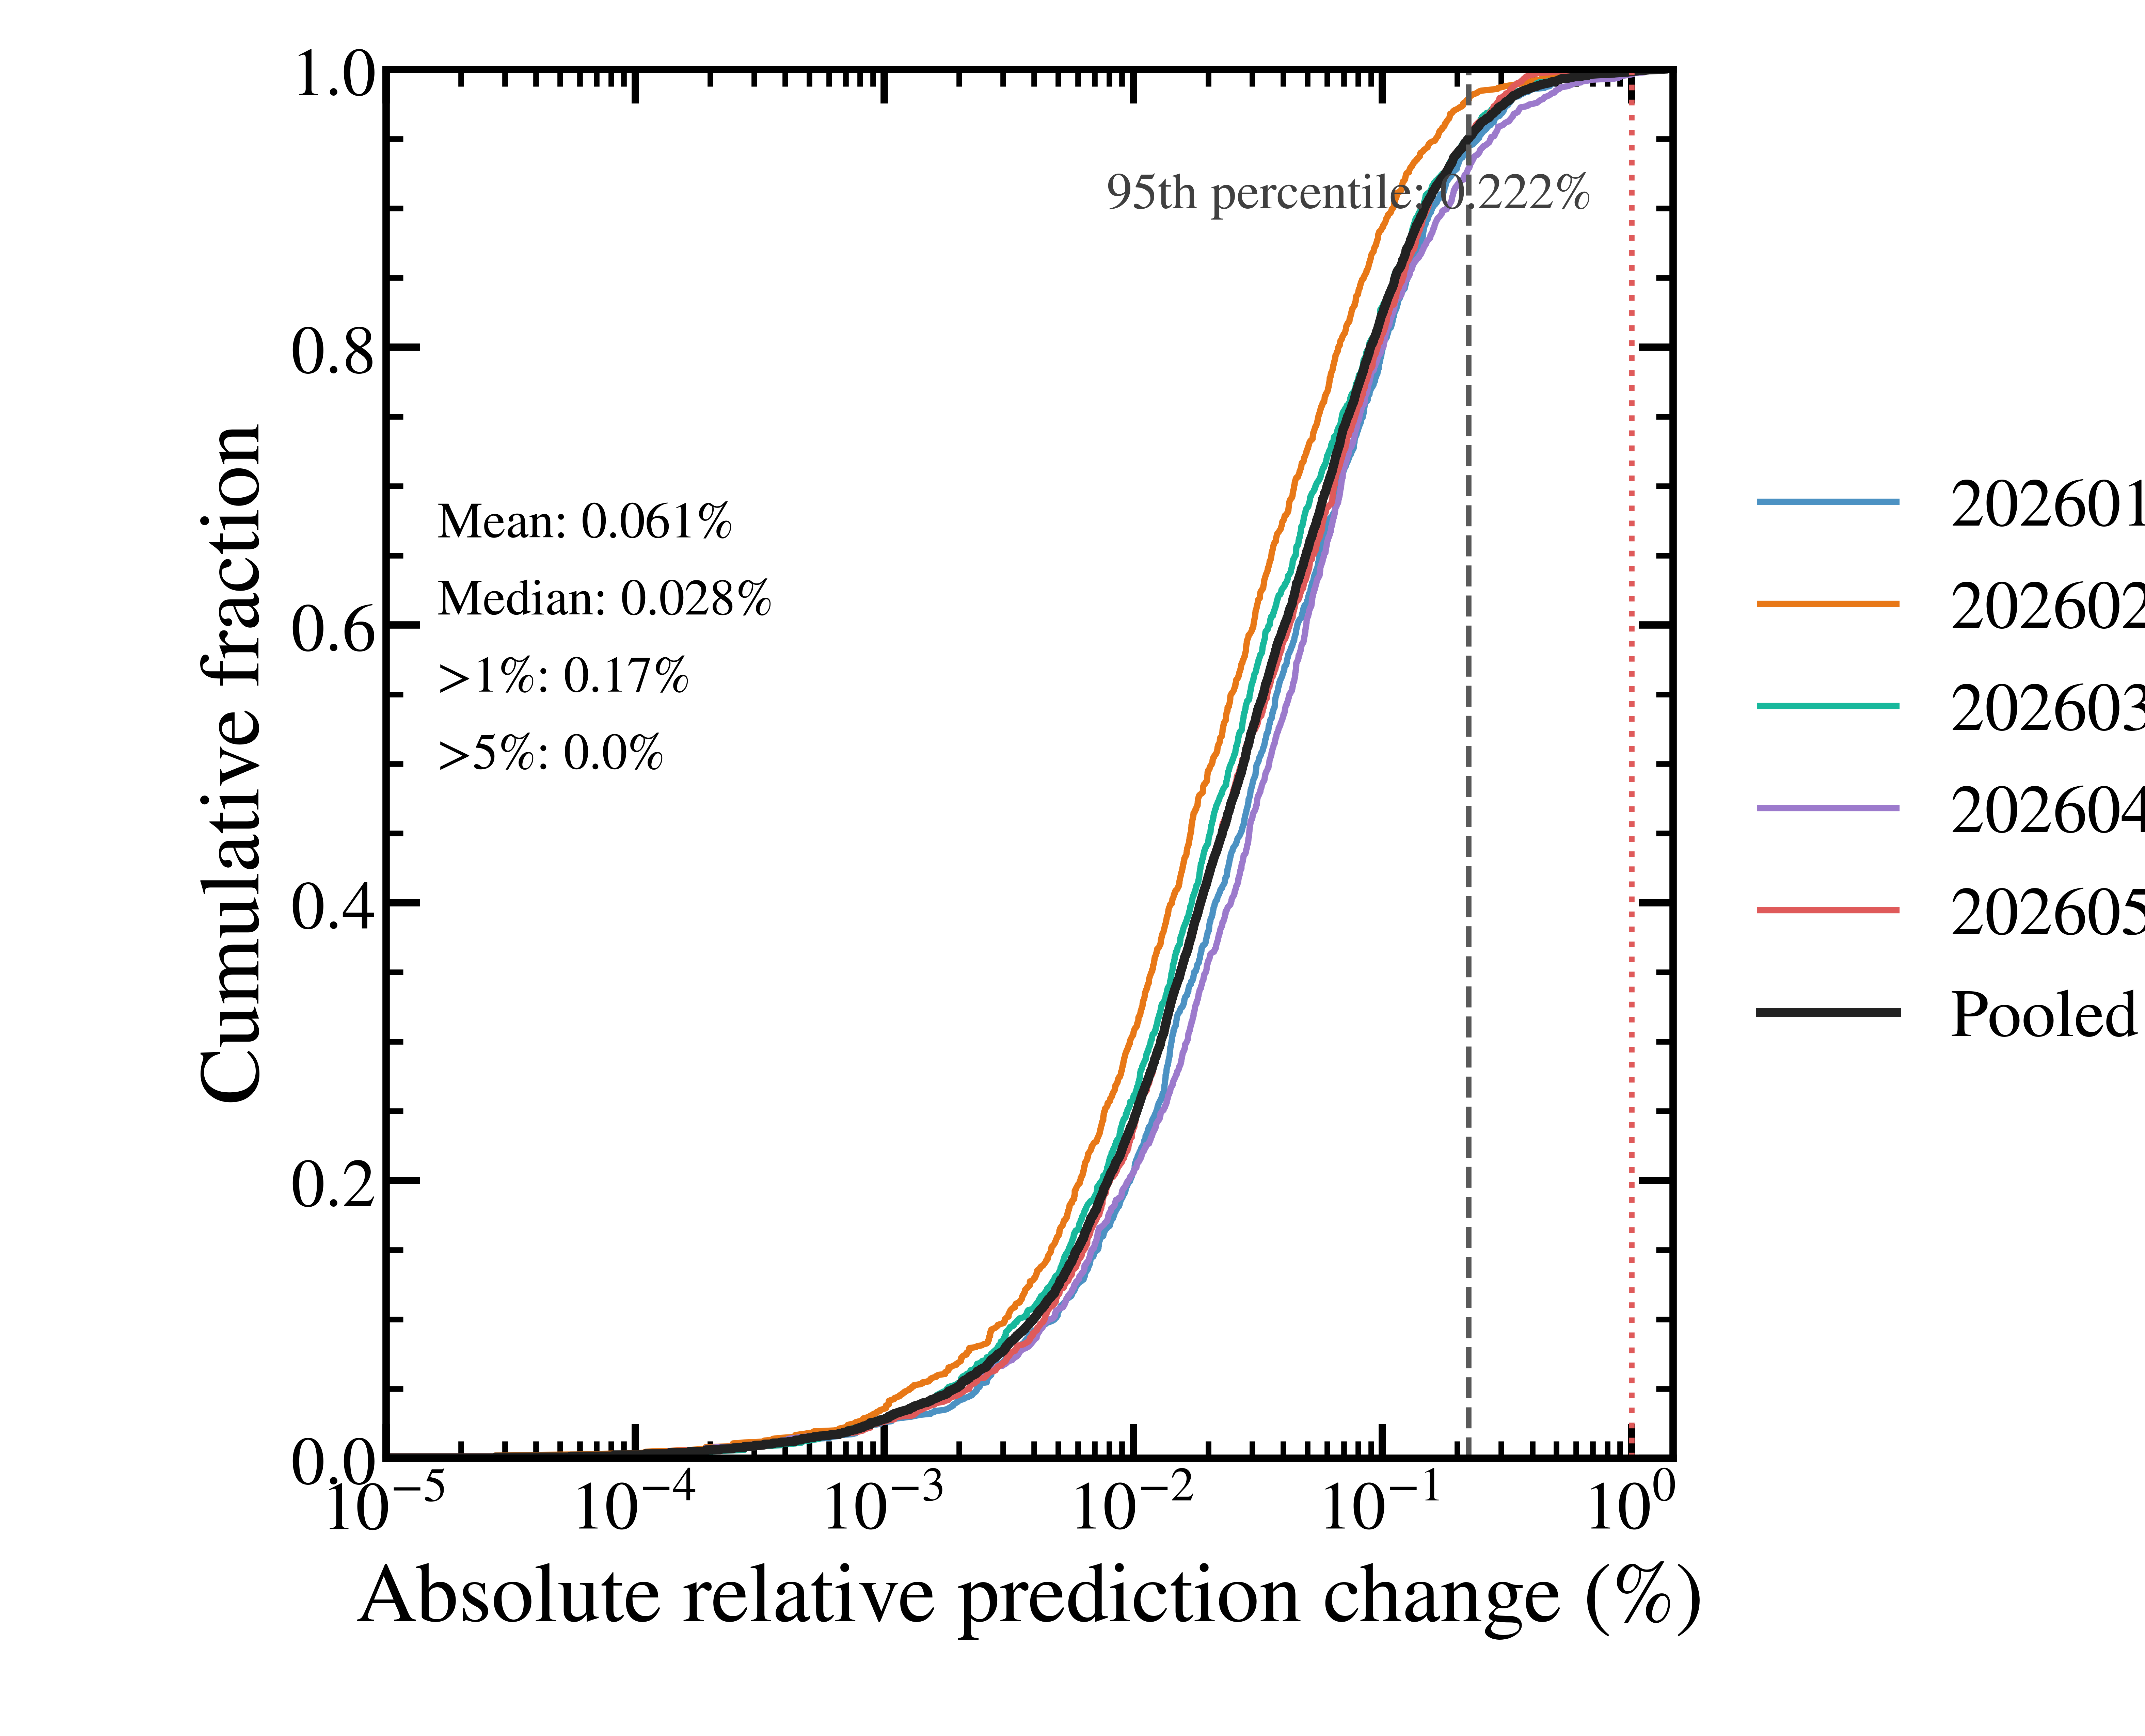

In [4]:
history = pd.read_csv(CODE / "data/mechanistic_interpretability/seed43/per_sample_predictions.csv")
relative = history.loc[~history.is_original, ["checkpoint_seed", "abs_relative_change_percent"]].copy()
fig, ax = plt.subplots(figsize=(10.5, 8.5), facecolor="white")
for seed, color in zip(sorted(relative.checkpoint_seed.unique()), [COLORS[k] for k in ("blue", "orange", "teal", "purple", "red")], strict=True):
    values = np.sort(relative.loc[relative.checkpoint_seed == seed, "abs_relative_change_percent"].to_numpy(float))
    ax.plot(values, np.arange(1, len(values) + 1) / len(values), color=color, lw=2.2, label=str(seed))
pooled = np.sort(relative["abs_relative_change_percent"].to_numpy(float))
ax.plot(pooled, np.arange(1, len(pooled) + 1) / len(pooled), color=COLORS["black"], lw=3.2, label="Pooled")
p95 = float(np.percentile(pooled, 95))
ax.axvline(p95, color="0.35", ls="--", lw=2.0)
ax.axvline(1.0, color=COLORS["red"], ls=":", lw=2.0)
ax.set(xscale="log", xlim=(max(pooled.min() * 0.8, 1e-5), pooled.max() * 1.1), ylim=(0, 1), xlabel="Absolute relative prediction change (%)", ylabel="Cumulative fraction")
ax.text(0.04, 0.70, f"Mean: {relative.abs_relative_change_percent.mean():.3f}%\nMedian: {relative.abs_relative_change_percent.median():.3f}%\n>1%: {(relative.abs_relative_change_percent > 1).mean() * 100:.2f}%\n>5%: {(relative.abs_relative_change_percent > 5).mean() * 100:.1f}%", transform=ax.transAxes, fontsize=18, va="top")
ax.text(0.56, 0.90, f"95th percentile: {p95:.3f}%", transform=ax.transAxes, fontsize=18, color="0.25")
style_axis(ax)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.subplots_adjust(left=0.18, right=0.78, bottom=0.16, top=0.96)
output = FIGURES / "legal_growth_history_sensitivity"
save_dual(fig, output, tight=False)
fig.savefig(output.with_suffix(".pdf"), facecolor="white")
plt.close(fig)
display(Image(filename=str(output.with_suffix(".png")), width=1000))
